In [1]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable — enable T4 GPU in Runtime settings.")

CUDA available: True
GPU: Tesla T4


In [2]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

OUTPUT_DIR = Path("/content/drive/MyDrive/TrustFact/results/week4")

print("Saved files:")
for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name)

Mounted at /content/drive
Saved files:
baseline_model_comparison.csv
best_lr_hyperparameters.csv
best_tuned_lr.joblib
linear_svm_pipeline.joblib
logistic_regression_pipeline.joblib
lr_classification_report.csv
lr_hyperparameter_search.csv
optimized_lr_classification_report.csv
optimized_lr_confusion_matrix.png
optimized_model_comparison.csv
statement_length_statistics.csv
svm_classification_report.csv
svm_confusion_matrix.png
svm_error_patterns.csv
svm_error_severity.csv
svm_error_severity.png
svm_prediction_errors.csv
train_label_counts.csv
train_validation_distribution.csv


In [5]:
%pip install -q transformers datasets accelerate scikit-learn

In [6]:
import transformers
import datasets
import accelerate

print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)

Transformers: 5.22.1
Datasets: 4.8.5
Accelerate: 1.15.0


In [7]:
from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/TrustFact")
DATA_DIR = BASE / "data/raw/liar"
OUTPUT_DIR = BASE / "results/week4/distilbert"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

columns = [
    "id", "label", "statement", "subject", "speaker",
    "speaker_job", "state", "party",
    "barely_true_count", "false_count",
    "half_true_count", "mostly_true_count",
    "pants_on_fire_count", "context"
]

train_df = pd.read_csv(
    DATA_DIR / "train.tsv",
    sep="\t",
    header=None,
    names=columns
)

valid_df = pd.read_csv(
    DATA_DIR / "valid.tsv",
    sep="\t",
    header=None,
    names=columns
)

print("Training:", train_df.shape)
print("Validation:", valid_df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training: (10240, 14)
Validation: (1284, 14)


In [8]:
labels = [
    "pants-fire",
    "false",
    "barely-true",
    "half-true",
    "mostly-true",
    "true"
]

label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}

train_df["label_id"] = train_df["label"].map(label2id)
valid_df["label_id"] = valid_df["label"].map(label2id)

assert train_df["label_id"].notna().all()
assert valid_df["label_id"].notna().all()

print(label2id)

{'pants-fire': 0, 'false': 1, 'barely-true': 2, 'half-true': 3, 'mostly-true': 4, 'true': 5}


In [9]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

sample = tokenizer(
    train_df["statement"].iloc[0],
    truncation=True,
    padding="max_length",
    max_length=128
)

print("Tokenization successful.")
print("Number of input tokens:", len(sample["input_ids"]))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenization successful.
Number of input tokens: 128


In [10]:
from datasets import Dataset

train_data = train_df[["statement", "label_id"]].copy()
valid_data = valid_df[["statement", "label_id"]].copy()

train_data["statement"] = train_data["statement"].fillna("")
valid_data["statement"] = valid_data["statement"].fillna("")

train_data = train_data.rename(columns={"label_id": "labels"})
valid_data = valid_data.rename(columns={"label_id": "labels"})

train_dataset = Dataset.from_pandas(
    train_data, preserve_index=False
)
valid_dataset = Dataset.from_pandas(
    valid_data, preserve_index=False
)

def tokenize_function(batch):
    return tokenizer(
        batch["statement"],
        truncation=True,
        max_length=128
    )

train_dataset = train_dataset.map(
    tokenize_function, batched=True
)
valid_dataset = valid_dataset.map(
    tokenize_function, batched=True
)

train_dataset = train_dataset.remove_columns(["statement"])
valid_dataset = valid_dataset.remove_columns(["statement"])

print("Training samples:", len(train_dataset))
print("Validation samples:", len(valid_dataset))
print("Dataset preparation successful!")

Map:   0%|          | 0/10240 [00:00<?, ? examples/s]

Map:   0%|          | 0/1284 [00:00<?, ? examples/s]

Training samples: 10240
Validation samples: 1284
Dataset preparation successful!


In [11]:
from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=6,
    id2label=id2label,
    label2id=label2id
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("DistilBERT classification model initialized!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT classification model initialized!


In [16]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, true_labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(true_labels, predictions),
        "macro_f1": f1_score(
            true_labels,
            predictions,
            average="macro",
            zero_division=0
        )
    }

In [17]:
from transformers import Trainer, TrainingArguments
import torch

assert torch.cuda.is_available(), "Enable a GPU before training."

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "checkpoints"),
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    logging_strategy="epoch",
    report_to="none",
    fp16=True,
    seed=42,
    data_seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer configured successfully!")

Trainer configured successfully!


In [18]:
train_result = trainer.train()

print("Training completed!")

metrics = trainer.evaluate()
print(metrics)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.720292,1.699427,0.245327,0.187253
2,1.617744,1.685021,0.250779,0.243899
3,1.485749,1.713819,0.260125,0.253645


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training completed!


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
1.485749,1.713819,3,0.260125,0.253645


{'eval_loss': 1.713818907737732, 'eval_accuracy': 0.2601246105919003, 'eval_macro_f1': 0.2536445968267816}


In [19]:
import json

MODEL_DIR = OUTPUT_DIR / "best_model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

trainer.save_model(str(MODEL_DIR))
tokenizer.save_pretrained(str(MODEL_DIR))

with open(OUTPUT_DIR / "distilbert_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("DistilBERT model and metrics saved to Google Drive.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT model and metrics saved to Google Drive.


,precision,recall,f1-score,support
pants-fire,0.349206,0.189655,0.245810,116.000000
false,0.278746,0.304183,0.290909,263.000000
barely-true,0.222222,0.135021,0.167979,237.000000
half-true,0.239067,0.330645,0.277496,248.000000
mostly-true,0.308370,0.278884,0.292887,251.000000
true,0.218182,0.284024,0.246787,169.000000
accuracy,0.260125,0.260125,0.260125,0.260125
macro avg,0.269299,0.253735,0.253645,1284.000000
weighted avg,0.264834,0.260125,0.256133,1284.000000


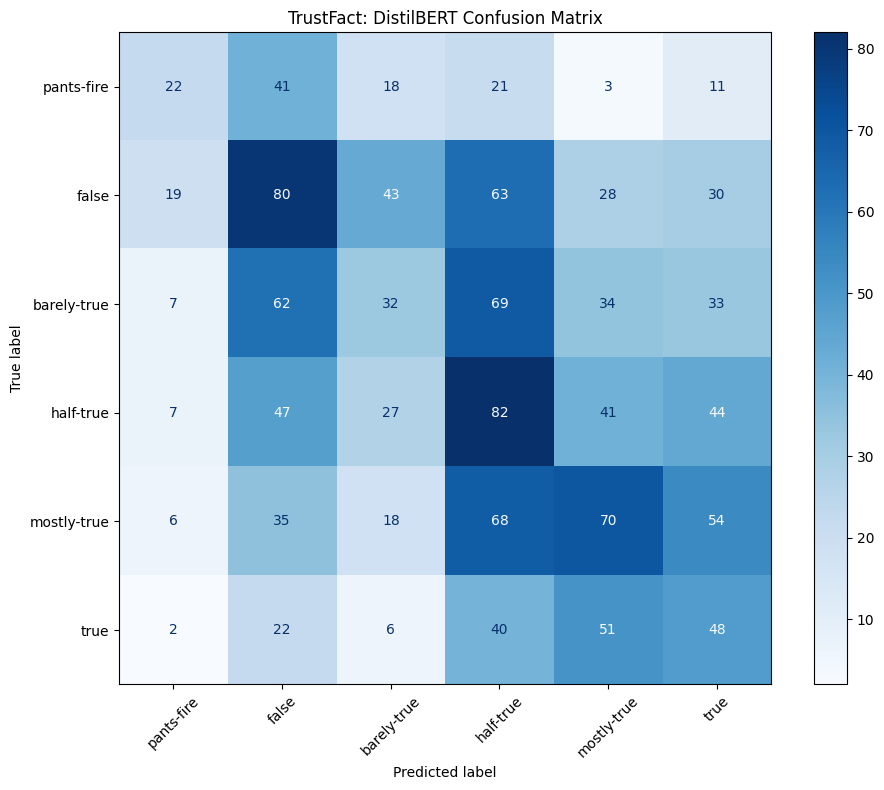

In [20]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pred_output = trainer.predict(valid_dataset)
predictions = np.argmax(pred_output.predictions, axis=1)

true_labels = valid_df["label_id"].to_numpy()

report = classification_report(
    true_labels,
    predictions,
    target_names=labels,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
display(report_df)

report_df.to_csv(
    OUTPUT_DIR / "distilbert_classification_report.csv"
)

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    true_labels,
    predictions,
    display_labels=labels,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("TrustFact: DistilBERT Confusion Matrix")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "distilbert_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [21]:
comparison = pd.DataFrame([
    ["Logistic Regression", 0.253115, 0.232384],
    ["Linear SVM", 0.262461, 0.258223],
    ["Optimized Logistic Regression", 0.267134, 0.261930],
    ["DistilBERT", 0.260125, 0.253645]
], columns=["Model", "Accuracy", "Macro-F1"])

comparison = comparison.sort_values(
    "Macro-F1", ascending=False
)

display(comparison)

comparison.to_csv(
    OUTPUT_DIR / "final_week4_model_comparison.csv",
    index=False
)

print("Final Week 4 comparison saved.")

,Model,Accuracy,Macro-F1
2,Optimized Logistic Regression,0.267134,0.261930
1,Linear SVM,0.262461,0.258223
3,DistilBERT,0.260125,0.253645
0,Logistic Regression,0.253115,0.232384


Final Week 4 comparison saved.


In [22]:
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np

prediction_output = trainer.predict(valid_dataset)
predictions = np.argmax(prediction_output.predictions, axis=1)
actual = valid_df["label_id"].to_numpy()

report = classification_report(
    actual,
    predictions,
    labels=list(range(6)),
    target_names=labels,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df)

report_df.to_csv(
    OUTPUT_DIR / "distilbert_detailed_evaluation.csv"
)

print("DistilBERT per-class evaluation saved.")

,precision,recall,f1-score,support
pants-fire,0.349206,0.189655,0.245810,116.000000
false,0.278746,0.304183,0.290909,263.000000
barely-true,0.222222,0.135021,0.167979,237.000000
half-true,0.239067,0.330645,0.277496,248.000000
mostly-true,0.308370,0.278884,0.292887,251.000000
true,0.218182,0.284024,0.246787,169.000000
accuracy,0.260125,0.260125,0.260125,0.260125
macro avg,0.269299,0.253735,0.253645,1284.000000
weighted avg,0.264834,0.260125,0.256133,1284.000000


DistilBERT per-class evaluation saved.


In [23]:
error_df = valid_df[["statement", "label"]].copy()

error_df["predicted_label"] = [
    id2label[int(i)] for i in predictions
]

error_df = error_df[
    error_df["label"] != error_df["predicted_label"]
]

error_patterns = (
    error_df.groupby(["label", "predicted_label"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(error_patterns.head(15))

error_patterns.to_csv(
    OUTPUT_DIR / "distilbert_error_patterns.csv",
    index=False
)

,label,predicted_label,count
1,barely-true,half-true,69
17,mostly-true,half-true,68
6,false,half-true,63
0,barely-true,false,62
19,mostly-true,true,54
28,true,mostly-true,51
11,half-true,false,47
14,half-true,true,44
5,false,barely-true,43
21,pants-fire,false,41
